# EMT2 · Kanıttan bulguya
9 Kasım 2026. Bu defter yalnız kayıtları ve graf kopyalarını okur. Model yüklemez, tahmin kilitlerini değiştirmez. Proje içindeki teslim klasöründen çalıştırılır.

In [1]:
from pathlib import Path
import pandas as pd, networkx as nx, json, hashlib
from IPython.display import display, Image
o=Path.cwd(); o=o if (o/'graf_v1').is_dir() else o/'EMT2_Teslim_v1'
q=o.parent/'reports/qa'
inventory=pd.read_csv(o/'EMT2_EVIDENCE_INVENTORY.csv')
display(inventory[['paket','deney','sonuc']].head(10))

,paket,deney,sonuc
0,WP00,Kaynak denetimi,"56 kimya, 53 ADR, 41 protein bağlantılı ilaç; ..."
1,WP01,Graf okuryazarlığı,4 ilaç ve 5 proteinden oluşan seçilmiş örnek: ...
2,WP02,J01 kayıt çözümü,"19.830 ana kayıt; 237 J01, 233 muhafazakâr ada..."
3,WP03,SIDER kimlik köprüsü,"233 adaydan 167 CID, 62 stereo eşleşmesi; 6.41..."
4,WP04,Moleküler kalite,"62/62 SMILES parse; 54 QC açık, 8 inceleme; ek..."
5,WP05,Protein özellikleri,"141 accession, 140 ayrı temiz dizi, 56 özellik..."
6,WP06,PPI kapsamı,İnsan PPI eşiği ≥700: 184 çift. K12 incelemesi...
7,WP07,İlişki şeması,"62 ilaç, 141 protein, 476 rol kenarı; 1061 PT,..."
8,WP08,B0 / B1 / B2,"paired54 AP: B0_like_B1 0,6438; B1 0,6556; B2 ..."
9,WP09,Protein mesaj geçişi,"Real 0,642880; noPPI 0,643021; karışık ortalam..."


## İnsan PPI: kimler paydaya giriyor?
Kenar tablosunda bulunmayan izole insan proteinlerini de n hesabına katmak gerekir. Aşağıdaki kontrol 63 düğümü kaynak taksonomisiyle kurar. Çap yalnız en büyük bileşen için hesaplanır.

,Protein,PPI çifti,Yoğunluk,Ana bileşen,Ana bileşende çap
0,63,184,0.094214,49,5


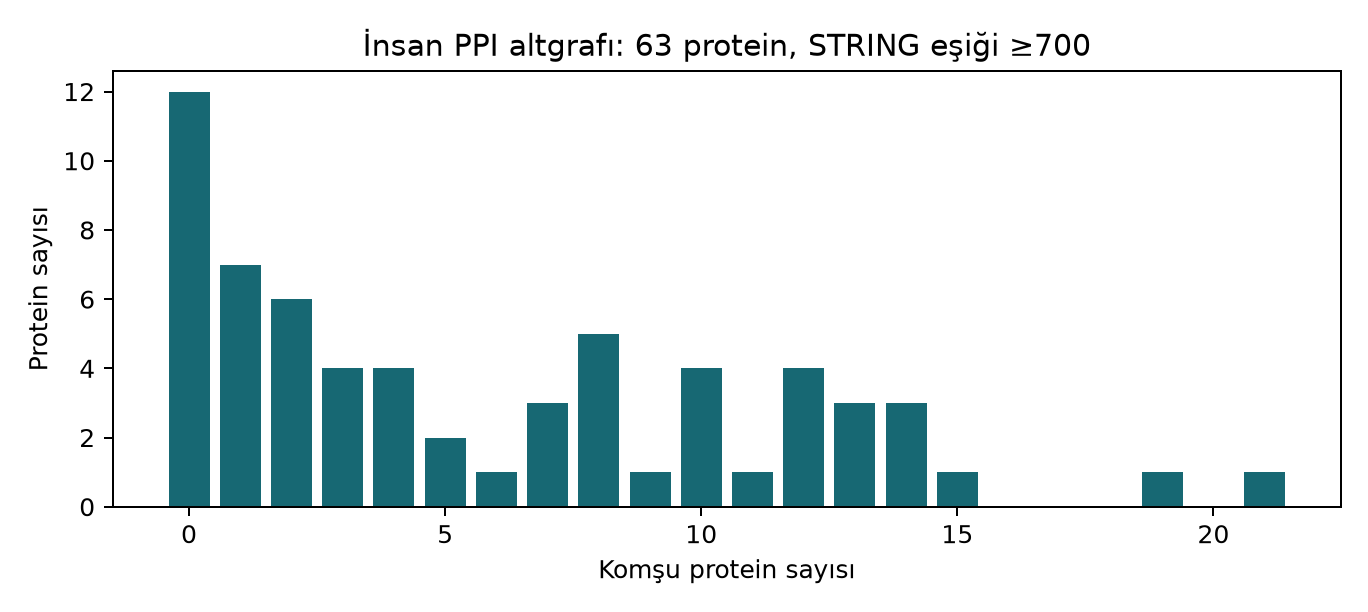

In [2]:
pp=pd.read_csv(o/'graf_v1/ppi_edge_provenance.csv').query("scenario == 'human_700'")
protein=pd.read_csv(o/'graf_v1/protein_string_mapping.csv')
g=nx.Graph();g.add_nodes_from(protein.loc[protein.taxid.eq(9606),'accession']);g.add_edges_from(pp[['accession1','accession2']].itertuples(index=False,name=None))
gc=g.subgraph(max(nx.connected_components(g),key=len))
assert (len(g),g.number_of_edges(),len(gc),nx.diameter(gc))==(63,184,49,5)
display(pd.DataFrame([{'Protein':len(g),'PPI çifti':g.number_of_edges(),'Yoğunluk':nx.density(g),'Ana bileşen':len(gc),'Ana bileşende çap':nx.diameter(gc)}]))
display(Image(filename=str(o/'graf_v1/derece.png')))

## Hangi model hangi soruya cevap veriyor?
Koşullu aralıklar aynı test tahminleri için yapısal grupları yeniden örnekler. Eşdeğerlik veya genel dış üstünlük ölçülmez.

,model,estimate,CI95_low,CI95_high
0,B2,0.626239,0.579200,0.670094
6,B1,0.655642,0.613111,0.692041
12,B0_all_train,0.646507,0.603990,0.685192
18,B0_like_B2,0.646604,0.604371,0.685339
24,B0_like_B1,0.643787,0.602130,0.681983
30,WP09_G_noPPI,0.643021,0.598498,0.684101
36,WP09_G_realPPI,0.642880,0.597754,0.684922
42,A0P0,0.642740,0.599338,0.684775
48,A0P1,0.643636,0.600493,0.685583
54,A1P0,0.645930,0.602034,0.686449


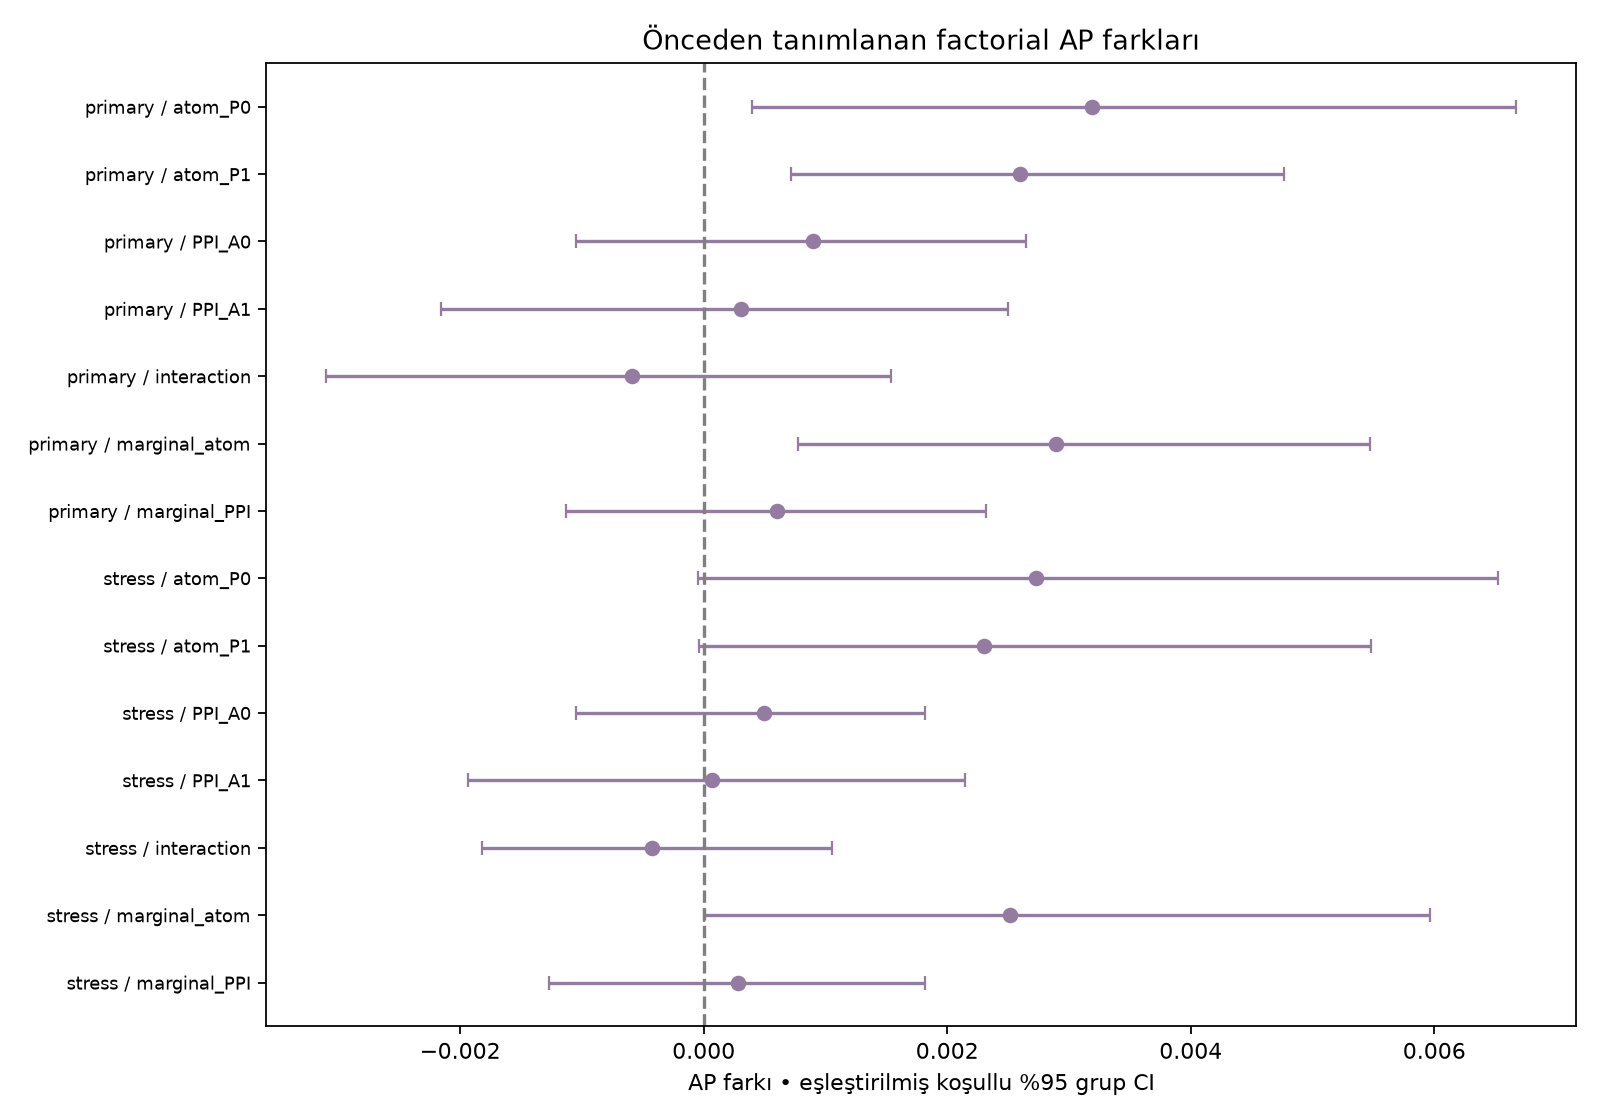

In [3]:
m=pd.read_csv(q/'WP10/training_v1/metrics_with_group_CI.csv')
display(m.query("scope=='paired54' and protocol=='primary' and metric=='drug_macro_AP'")[['model','estimate','CI95_low','CI95_high']])
display(Image(filename=str(o.parent/'reports/figures/WP10/training_v1/04_factorial_contrasts.png')))

## Tedizolid: kaynak ile model farklı ölçülerdir
Beş modelin kayıt sıralama puanları arasında aritmetik ortalama alınır; farklı modellerin logit SHAP değerleri bu ortalamanın ayrışımı sayılmaz.

,rank,term_tr_editorial,record_ranking_score,source_terms,source_pages,human_review
0,1,İshal,0.864200,Diyare,7,PENDING
1,2,Döküntü,0.855534,Döküntü,7,PENDING
2,3,Anafilaktik şok,0.854920,NaN,NaN,PENDING
3,4,Kusma,0.847858,Kusma,7,PENDING
4,5,Karın ağrısı,0.823995,Karın ağrısı,7,PENDING
5,6,Gastrointestinal ağrı,0.823995,Karın ağrısı,7,PENDING
6,7,Aşırı duyarlılık,0.821030,İlaca aşırı duyarlılık,6,PENDING
7,8,Kaşıntı,0.817670,Prürit | Genel prürit | Alerjik prürit,7,PENDING
8,9,Trombositopeni,0.816634,trombositopeni | platelet düşüşü,2 | 3,PENDING
9,10,Ürtiker,0.805517,Ürtiker,7,PENDING


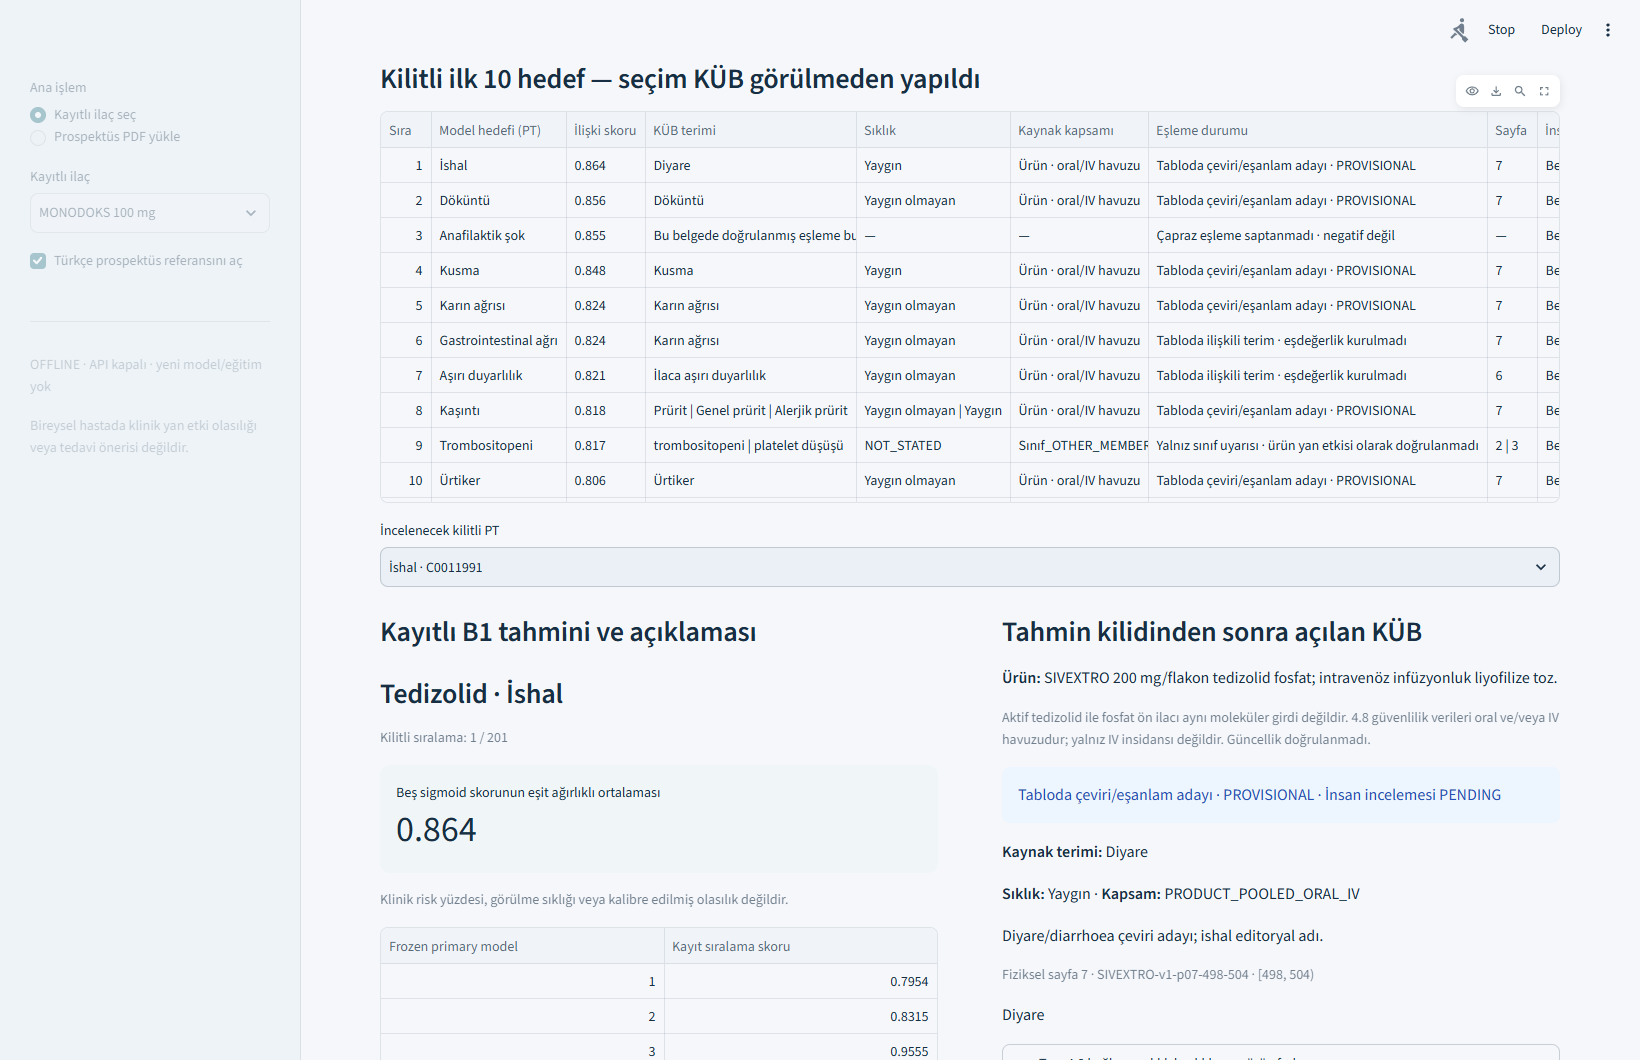

In [4]:
t=pd.read_csv(q/'WP13/WP13_EXTERNAL_REFERENCE_COMPARISON_v1/top10_comparison.csv')
a=t[[f'fold{i}_score' for i in range(1,6)]].mean(axis=1)
assert (a-t.record_ranking_score).abs().max()<1e-12 and len(t)==10
display(t[['rank','term_tr_editorial','record_ranking_score','source_terms','source_pages','human_review']])
display(Image(filename=str(o/'ekranlar/08_ilk10.png'),width=900))

## Kayda geçmeyen ne?
Boş kaynak terimi klinik yokluk değildir. Eşlenmemiş hedef ve uzman kararı bekleyen kaynaklar kendi durumlarıyla korunmalıdır.

In [5]:
display(t.reference_status.value_counts().rename_axis('Durum').reset_index(name='Hedef'))
assert t.human_review.eq('PENDING').all()
display(pd.read_csv(o/'NOTEBOOK_DENETIMI.csv')[['kod','yurutulmus','png','html','hata']].sum().to_frame('62 tarihsel notebook toplamı'))

,Durum,Hedef
0,TABLE_TRANSLATION_CANDIDATE,6
1,TABLE_RELATED_NOT_EQUIVALENT,2
2,NOT_IDENTIFIED_IN_REFERENCE_NOT_NEGATIVE,1
3,CLASS_WARNING_ONLY,1


,62 tarihsel notebook toplamı
kod,358
yurutulmus,358
png,240
html,742
hata,0
